In [65]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

HERE = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [HERE, *HERE.parents] if (p / 'data' / 'train.csv').exists()), HERE)
if not (PROJECT_ROOT / 'data' / 'train.csv').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / 'data' / 'train.csv'
df = pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH}')
print('Shape:', df.shape)
df.head()

Loaded /Users/marklim/Masters/CS5228/CS5228-proj-ML/data/train.csv
Shape: (150000, 11)


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800


#### Cleaning the train dataset

In [66]:
TARGET = 'MONTHLY_RENT'
work = df.copy()

# Remove exact duplicate rows from the baseline dataset.
work = work.drop_duplicates().reset_index(drop=True)

# Normalize all text fields: trim whitespace, collapse repeated spaces, and lowercase.
text_columns = work.select_dtypes(include=['object', 'string']).columns
for column in text_columns:
    work[column] = (work[column].astype('string').str.strip()
                    .str.replace(r'\s+', ' ', regex=True).str.lower())

# Standardize common street-type spellings and abbreviations.
street_replacements = {
    r'\bavenue\b': 'ave', r'\broad\b': 'rd',
    r'\bstreet\b': 'st', r'\bdrive\b': 'dr',
    r'\bcentral\b': 'ctrl', r'\bplace\b': 'pl',
    r'\bclose\b': 'cl', r'\bcrescent\b': 'cres',
    r'\blane\b': 'ln', r'\blink\b': 'link',
    r'\bparkway\b': 'pkwy', r'\bterrace\b': 'ter',
    r'\bview\b': 'vw', r'\bwalk\b': 'walk',
}
for pattern, replacement in street_replacements.items():
    work['STREET'] = work['STREET'].str.replace(pattern, replacement, regex=True)
work['STREET'] = work['STREET'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Canonicalize known category variants. These mappings make spelling, case, and
# formatting differences resolve to one category before one-hot encoding.
work['FLAT_TYPE'] = work['FLAT_TYPE'].replace({
    '1 room': '1-room', '2 room': '2-room', '3 room': '3-room',
    '4 room': '4-room', '5 room': '5-room',
})
work['FURNISHED'] = work['FURNISHED'].replace({
    'yes': 1, 'y': 1, 'true': 1, '1': 1,
    'no': 0, 'n': 0, 'false': 0, '0': 0,
}).astype('Int64')

work['approval_date'] = pd.to_datetime(work['RENT_APPROVAL_DATE'], format='%Y-%m', errors='coerce')
work['RENT_YEAR'] = work['approval_date'].dt.year
work['RENT_MONTH'] = work['approval_date'].dt.month
work['RENT_QUARTER'] = work['approval_date'].dt.quarter

### Join with HDB data to get geospatial features

In [67]:
hdb_raw = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-hdb-block.csv', dtype={'POSTAL_CODE': 'string'})

STREET_REPLACEMENTS = {r'\bavenue\b':'ave', r'\broad\b':'rd', r'\bstreet\b':'st', r'\bdrive\b':'dr', r'\bcentral\b':'ctrl', r'\bplace\b':'pl', r'\bclose\b':'cl', r'\bcrescent\b':'cres', r'\blane\b':'ln', r'\bparkway\b':'pkwy', r'\bterrace\b':'ter', r'\bview\b':'vw'}
def normalize_text(s):
    return s.astype('string').str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
def clean_common(frame):
    out = frame.copy()
    for col in out.select_dtypes(include=['object','string']).columns: out[col] = normalize_text(out[col])
    if 'STREET' in out:
        for pattern, replacement in STREET_REPLACEMENTS.items(): out['STREET'] = out['STREET'].str.replace(pattern, replacement, regex=True)
        out['STREET'] = out['STREET'].str.replace(r'\s+', ' ', regex=True).str.strip()
    if 'FLAT_TYPE' in out: out['FLAT_TYPE'] = out['FLAT_TYPE'].replace({'1 room':'1-room','2 room':'2-room','3 room':'3-room','4 room':'4-room','5 room':'5-room'})
    if 'FURNISHED' in out: out['FURNISHED'] = out['FURNISHED'].replace({'yes':1,'y':1,'true':1,'1':1,'no':0,'n':0,'false':0,'0':0}).astype('Int64')
    return out

hdb = clean_common(hdb_raw)
hdb['ADDRESS_KEY'] = hdb['TOWN'] + '|' + hdb['BLOCK'] + '|' + hdb['STREET']
work['ADDRESS_KEY'] = work['TOWN'] + '|' + work['BLOCK'] + '|' + work['STREET']


hdb = hdb.drop_duplicates('ADDRESS_KEY', keep='first')
geo_columns = ['ADDRESS_KEY','POSTAL_CODE','LATITUDE','LONGITUDE','MAX_FLOOR','YEAR_COMPLETED','SUBZONE','PLANNING_AREA','REGION']
work_geo = work.merge(hdb[geo_columns], on='ADDRESS_KEY', how='left', validate='many_to_one')
work_geo['HDB_BLOCK_MATCHED'] = work_geo['LATITUDE'].notna().astype('int8')
work_geo['BUILDING_AGE'] = work_geo['RENT_YEAR'] - pd.to_numeric(work_geo['YEAR_COMPLETED'], errors='coerce')
# train_geo = postcode_geocoder.transform(train_geo)
# train_geo = floor_transformer.transform(train_geo)
print('HDB match rate:', f"{work_geo['HDB_BLOCK_MATCHED'].mean():.2%}")
work_geo.head()

HDB match rate: 100.00%


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,...,POSTAL_CODE,LATITUDE,LONGITUDE,MAX_FLOOR,YEAR_COMPLETED,SUBZONE,PLANNING_AREA,REGION,HDB_BLOCK_MATCHED,BUILDING_AGE
0,2021-01,punggol,604a,punggol rd,4-room,model a,93.0,1,2012,0.0,...,821604,1.404310,103.907413,16,2010,waterway east,punggol,north-east region,1,11
1,2021-01,sengkang,290c,compassvale cres,5-room,improved,110.0,1,2001,0.0,...,543290,1.397018,103.897535,15,2000,sengkang town centre,sengkang,north-east region,1,21
2,2021-01,queenstown,5,ghim moh rd,3-room,improved,65.0,1,1976,0.0,...,270005,1.312693,103.788309,15,1975,ghim moh,queenstown,central region,1,46
3,2021-01,sengkang,436b,fernvale rd,4-room,model a,96.0,1,2010,0.0,...,792436,1.392878,103.876976,21,2008,fernvale,sengkang,north-east region,1,13
4,2021-01,sembawang,467b,admiralty dr,4-room,premium apartment,102.0,1,2001,0.0,...,752467,1.451141,103.813630,16,1999,sembawang north,sembawang,north region,1,22


In [68]:
work_geo.columns

Index(['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE',
       'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE',
       'FEE', 'MONTHLY_RENT', 'approval_date', 'RENT_YEAR', 'RENT_MONTH',
       'RENT_QUARTER', 'ADDRESS_KEY', 'POSTAL_CODE', 'LATITUDE', 'LONGITUDE',
       'MAX_FLOOR', 'YEAR_COMPLETED', 'SUBZONE', 'PLANNING_AREA', 'REGION',
       'HDB_BLOCK_MATCHED', 'BUILDING_AGE'],
      dtype='str')

### Rental price heat map by planning subzone

The map uses the median `MONTHLY_RENT` of geocoded HDB rental records within each subzone.

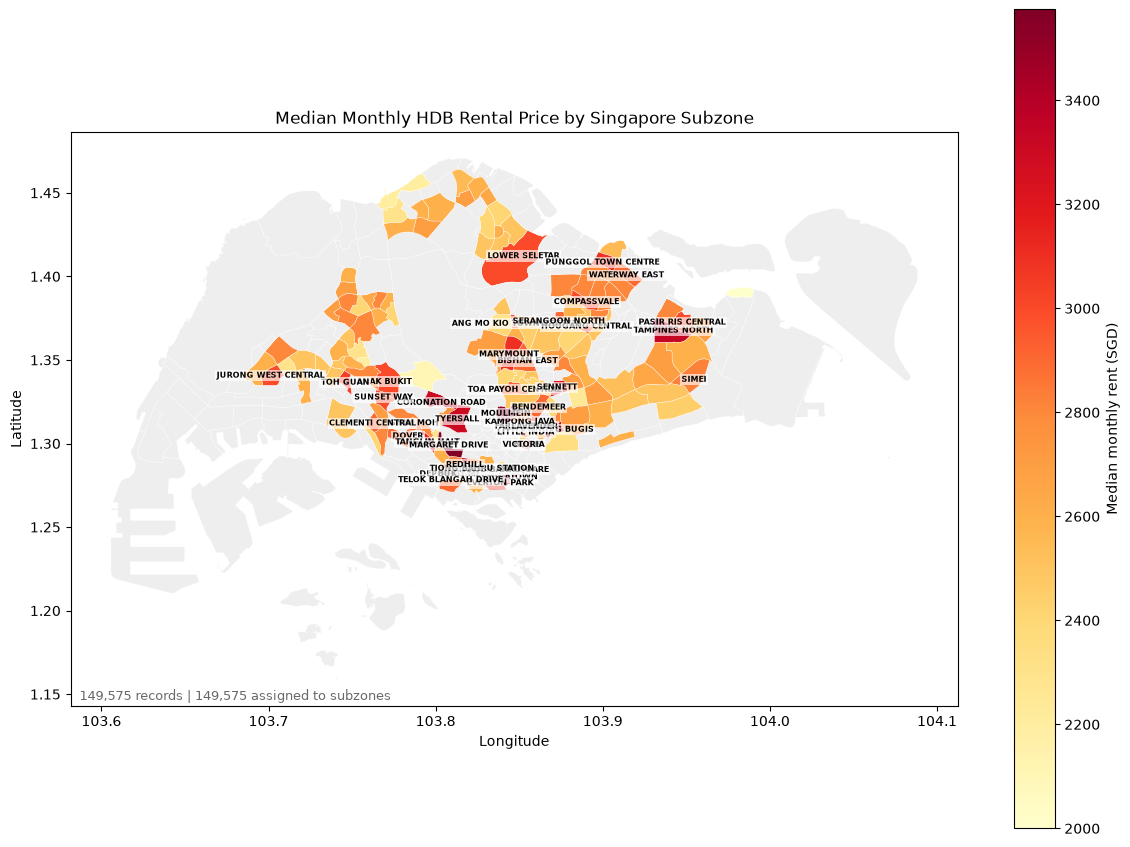

In [69]:
import json
from matplotlib import cm, colors
from matplotlib.collections import PolyCollection
import matplotlib.pyplot as plt

GEOJSON_PATH = PROJECT_ROOT / 'data' / 'MasterPlan2019SubzoneBoundaryNoSeaGEOJSON.geojson'
with GEOJSON_PATH.open(encoding='utf-8') as f:
    subzones = json.load(f)['features']

def polygon_parts(geometry):
    # Return the exterior ring for Polygon and MultiPolygon geometries.
    if geometry['type'] == 'Polygon':
        return [geometry['coordinates'][0]]
    return [polygon[0] for polygon in geometry['coordinates']]

# work_geo already contains the HDB block's authoritative SUBZONE. Using it
# avoids an expensive point-in-polygon calculation for every rental row.
rent_points = work_geo[['SUBZONE', 'MONTHLY_RENT']].rename(columns={'SUBZONE': 'SUBZONE_N'}).copy()
rent_points['SUBZONE_N'] = rent_points['SUBZONE_N'].astype('string').str.strip().str.upper()
rent_points['MONTHLY_RENT'] = pd.to_numeric(rent_points['MONTHLY_RENT'], errors='coerce')
rent_by_subzone = (rent_points.dropna(subset=['SUBZONE_N', 'MONTHLY_RENT'])
                    .groupby('SUBZONE_N')['MONTHLY_RENT']
                    .agg(median_rent='median', rental_records='size')
                    .reset_index())
rent_lookup = rent_by_subzone.set_index('SUBZONE_N')['median_rent'].to_dict()

polygons, values = [], []
for feature in subzones:
    name = feature['properties']['SUBZONE_N']
    for ring in polygon_parts(feature['geometry']):
        polygons.append(ring)
        values.append(rent_lookup.get(name, float('nan')))

valid_rents = rent_by_subzone['median_rent']
norm = colors.Normalize(vmin=valid_rents.min(), vmax=valid_rents.max())
cmap = plt.colormaps.get_cmap('YlOrRd').copy()
cmap.set_bad('#eeeeee')
fig, ax = plt.subplots(figsize=(12, 12))
collection = PolyCollection(polygons, array=np.asarray(values, dtype=float), cmap=cmap, norm=norm, edgecolor='white', linewidth=0.25)
ax.add_collection(collection)
ax.autoscale()
ax.set_aspect('equal')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Median Monthly HDB Rental Price by Singapore Subzone')
for feature in subzones:
    name = feature['properties']['SUBZONE_N']
    rent = rent_lookup.get(name)
    if rent is not None and rent > 2800:
        rings = polygon_parts(feature['geometry'])
        points = [point for ring in rings for point in ring]
        centroid_lon = np.mean([point[0] for point in points])
        centroid_lat = np.mean([point[1] for point in points])
        ax.text(centroid_lon, centroid_lat, name, ha='center', va='center', fontsize=6, fontweight='bold', color='black', bbox=dict(facecolor='white', edgecolor='none', alpha=0.65, pad=1))
fig.colorbar(collection, ax=ax, label='Median monthly rent (SGD)', shrink=0.7)
ax.text(0.01, 0.01, f'{len(rent_points):,} records | {rent_points["SUBZONE_N"].notna().sum():,} assigned to subzones', transform=ax.transAxes, fontsize=9, color='dimgray')
plt.tight_layout()
plt.show()

### Nearest MRT station and bus stop

Distances are calculated as straight-line (geodesic) distances from each HDB block.

In [70]:
from pathlib import Path

from scipy.spatial import cKDTree

mrt = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-mrt-stations.csv')
bus = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-bus-stops.csv')
bus = bus.rename(columns={'Latitude': 'LATITUDE', 'Longitude': 'LONGITUDE'})

def nearest_locations(points, locations, name_column, prefix):
    lat_scale = 111.32
    mean_lat = np.deg2rad(pd.concat([points['LATITUDE'], locations['LATITUDE']]).mean())
    def project(frame):
        return np.column_stack((frame['LONGITUDE'] * np.cos(mean_lat) * lat_scale, frame['LATITUDE'] * lat_scale))
    tree = cKDTree(project(locations))
    distance_km, nearest_index = tree.query(project(points), k=1)
    result = pd.DataFrame(index=points.index)
    result[f'{prefix}_NAME'] = locations.iloc[nearest_index][name_column].to_numpy()
    result[f'{prefix}_DISTANCE_KM'] = distance_km
    return result

transport_features = pd.concat([
    nearest_locations(work_geo, mrt, 'NAME', 'MRT'),
    nearest_locations(work_geo, bus, 'Description', 'BUS_STOP'),
], axis=1)
work_geo_transport = pd.concat([work_geo.reset_index(drop=True), transport_features.reset_index(drop=True)], axis=1)

display(work_geo_transport[['STREET', 'BLOCK', 'MRT_NAME', 'MRT_DISTANCE_KM', 'BUS_STOP_NAME', 'BUS_STOP_DISTANCE_KM']].head())

,STREET,BLOCK,MRT_NAME,MRT_DISTANCE_KM,BUS_STOP_NAME,BUS_STOP_DISTANCE_KM
0,punggol rd,604a,punggol mrt/lrt station,0.557279,Blk 604A,0.037602
1,compassvale cres,290c,sengkang mrt/lrt station,0.635085,Blk 291A,0.170667
2,ghim moh rd,5,buona vista mrt station,0.626593,Blk 3,0.146237
3,fernvale rd,436b,sengkang mrt/lrt station,2.072135,Blk 436A,0.119677
4,admiralty dr,467b,sembawang mrt station,0.763197,Bet Blks 357/359,0.298647


### MRT stations and bus stops within walking-distance thresholds

In [71]:
from scipy.spatial import cKDTree

def projected_coordinates(frame, mean_lat):
    metres_per_degree = 111320
    return np.column_stack((
        frame['LONGITUDE'].to_numpy(dtype=float) * np.cos(mean_lat) * metres_per_degree,
        frame['LATITUDE'].to_numpy(dtype=float) * metres_per_degree,
    ))

mean_lat = np.deg2rad(pd.concat([
    work_geo['LATITUDE'], mrt['LATITUDE'], bus['LATITUDE']
]).mean())
hdb_coordinates = projected_coordinates(work_geo, mean_lat)
mrt_tree = cKDTree(projected_coordinates(mrt, mean_lat))
bus_tree = cKDTree(projected_coordinates(bus, mean_lat))

transport_counts = pd.DataFrame(index=work_geo.index)
for distance_m in (250, 750):
    transport_counts[f'MRT_WITHIN_{distance_m}M'] = [
        len(indices) for indices in mrt_tree.query_ball_point(hdb_coordinates, r=distance_m)
    ]
    transport_counts[f'BUS_STOPS_WITHIN_{distance_m}M'] = [
        len(indices) for indices in bus_tree.query_ball_point(hdb_coordinates, r=distance_m)
    ]

work_geo_transport = pd.concat([
    work_geo_transport.reset_index(drop=True),
    transport_counts.reset_index(drop=True),
], axis=1)

display(work_geo_transport[[
    'STREET', 'BLOCK', 'MRT_WITHIN_250M', 'MRT_WITHIN_750M',
    'BUS_STOPS_WITHIN_250M', 'BUS_STOPS_WITHIN_750M'
]].head())

,STREET,BLOCK,MRT_WITHIN_250M,MRT_WITHIN_750M,BUS_STOPS_WITHIN_250M,BUS_STOPS_WITHIN_750M
0,punggol rd,604a,0,3,4,37
1,compassvale cres,290c,0,2,2,38
2,ghim moh rd,5,0,2,4,29
3,fernvale rd,436b,0,0,5,32
4,admiralty dr,467b,0,0,0,33


### Nearest school

In [72]:
schools = pd.read_csv(PROJECT_ROOT / 'data' / 'sg-schools.csv')

mean_lat = np.deg2rad(pd.concat([
    work_geo['LATITUDE'], schools['LATITUDE']
]).mean())
metres_per_degree = 111320

def project_coordinates(frame):
    return np.column_stack((
        frame['LONGITUDE'].to_numpy(dtype=float) * np.cos(mean_lat) * metres_per_degree,
        frame['LATITUDE'].to_numpy(dtype=float) * metres_per_degree,
    ))

school_tree = cKDTree(project_coordinates(schools))
school_distance_m, school_index = school_tree.query(project_coordinates(work_geo), k=1)

work_geo_transport['NEAREST_SCHOOL'] = schools.iloc[school_index]['NAME'].to_numpy()
work_geo_transport['SCHOOL_DISTANCE_KM'] = school_distance_m / 1000

display(work_geo_transport[[
    'STREET', 'BLOCK', 'NEAREST_SCHOOL', 'SCHOOL_DISTANCE_KM'
]].head())

FEATURES_OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'hdb_features_before_accessibility.csv'
work_geo_transport.to_csv(FEATURES_OUTPUT_PATH, index=False)
print(f'Saved {len(work_geo_transport):,} rows and {len(work_geo_transport.columns):,} features to {FEATURES_OUTPUT_PATH}')

,STREET,BLOCK,NEAREST_SCHOOL,SCHOOL_DISTANCE_KM
0,punggol rd,604a,punggol view primary school,0.267819
1,compassvale cres,290c,compassvale secondary school,0.275222
2,ghim moh rd,5,henry park primary school,0.629340
3,fernvale rd,436b,sengkang green primary school,0.195715
4,admiralty dr,467b,canberra secondary school,0.236951


Saved 149,575 rows and 36 features to /Users/marklim/Masters/CS5228/CS5228-proj-ML/data/processed/hdb_features_before_accessibility.csv


### Public-transport accessibility to proxy destinations

### Accessibility score calculation

For each unique HDB coordinate, the notebook requests public-transport travel time to five representative proxy destinations. Travel times are converted from seconds to minutes. The destination-specific columns also retain the number of transfers and walking distance returned by the routing API.

- `mean_travel_time_min`: arithmetic mean travel time across all proxy destinations.
- `median_travel_time_min`: median travel time across all proxy destinations.
- `cbd_travel_time_min`: travel time to Raffles Place.
- `regional_hub_travel_time_min`: shortest travel time to Jurong East or Tampines Regional Centre.
- `essential_services_time_min`: travel time to Singapore General Hospital.
- `education_access_time_min`: travel time to NUS.
- `ACCESSIBILITY_SCORE`: negative mean travel time (`-mean_travel_time_min`), so higher values indicate better accessibility.

A missing travel time indicates that the routing request failed or returned no usable itinerary; aggregate values use the remaining valid destinations.

In [73]:
import sys
import time
from concurrent.futures import ThreadPoolExecutor
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.get_distance_to_place import get_travel_time

proxy_locations = {
    'raffles_place': '1.2839,103.8515',       # CBD employment
    'jurong_east': '1.3331,103.7423',         # western regional hub
    'tampines_regional_centre': '1.3530,103.9452',  # eastern regional hub
    'nus': '1.2966,103.7764',                  # education
    'singapore_general_hospital': '1.2793,103.8350', # healthcare
}

# Query each unique coordinate once, then merge results back to all rental rows.
route_points = work_geo_transport[['STREET', 'LATITUDE', 'LONGITUDE']].drop_duplicates(['LATITUDE', 'LONGITUDE']).copy()
route_results = route_points[['LATITUDE', 'LONGITUDE']].copy()
route_points = route_points.rename(columns={
    'STREET': 'street', 'LATITUDE': 'approx_lat', 'LONGITUDE': 'approx_lon'
})

cache_path = PROJECT_ROOT / 'data' / 'processed' / 'accessibility_route_cache.csv'
route_cache = pd.read_csv(cache_path) if cache_path.exists() else pd.DataFrame(columns=['key', 'destination', 'time_seconds', 'transfers', 'walking_distance_m'])
def make_key(lat, lon, destination): return f'{lat:.6f}|{lon:.6f}|{destination}'
def request_route(item):
    row, destination, coordinates, key = item
    try: result = get_travel_time(row, coordinates)
    except Exception: result = {}
    return {'key': key, 'destination': destination, 'time_seconds': result.get('time_taken_by_public_transport', np.nan), 'transfers': result.get('transfers', np.nan), 'walking_distance_m': result.get('walking_distance', np.nan)}

for destination, coordinates in proxy_locations.items():
    keys = [make_key(lat, lon, destination) for lat, lon in zip(route_results['LATITUDE'], route_results['LONGITUDE'])]
    cached = set(route_cache.loc[route_cache['destination'].eq(destination), 'key'])
    missing = [(row, destination, coordinates, key) for (_, row), key in zip(route_points.iterrows(), keys) if key not in cached]
    print(f'{destination}: {len(missing):,} uncached requests')
    for start in range(0, len(missing), 250):
        batch_start = time.monotonic()
        batch = missing[start:start + 250]
        with ThreadPoolExecutor(max_workers=20) as pool: results = list(pool.map(request_route, batch))
        route_cache = pd.concat([route_cache, pd.DataFrame(results)], ignore_index=True).drop_duplicates('key', keep='last')
        route_cache.to_csv(cache_path, index=False)
        if start + 250 < len(missing): time.sleep(max(0, 60 - (time.monotonic() - batch_start)))
    current = route_cache.set_index('key').reindex(keys)
    route_results[f'{destination}_time_min'] = current['time_seconds'].to_numpy() / 60
    route_results[f'{destination}_transfers'] = current['transfers'].to_numpy()
    route_results[f'{destination}_walking_distance_m'] = current['walking_distance_m'].to_numpy()

work_geo_transport = work_geo_transport.merge(route_results, on=['LATITUDE', 'LONGITUDE'], how='left', validate='many_to_one')

time_columns = [f'{destination}_time_min' for destination in proxy_locations]
work_geo_transport['mean_travel_time_min'] = work_geo_transport[time_columns].mean(axis=1)
work_geo_transport['median_travel_time_min'] = work_geo_transport[time_columns].median(axis=1)
work_geo_transport['cbd_travel_time_min'] = work_geo_transport['raffles_place_time_min']
work_geo_transport['regional_hub_travel_time_min'] = work_geo_transport[[
    'jurong_east_time_min', 'tampines_regional_centre_time_min'
]].min(axis=1)
work_geo_transport['essential_services_time_min'] = work_geo_transport['singapore_general_hospital_time_min']
work_geo_transport['education_access_time_min'] = work_geo_transport['nus_time_min']
work_geo_transport['ACCESSIBILITY_SCORE'] = -work_geo_transport['mean_travel_time_min']

display(work_geo_transport[[
    'ADDRESS_KEY', 'mean_travel_time_min', 'median_travel_time_min',
    'cbd_travel_time_min', 'regional_hub_travel_time_min',
    'essential_services_time_min', 'education_access_time_min',
    'ACCESSIBILITY_SCORE'
]].head())

raffles_place: 8,656 uncached requests
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
429
4

,ADDRESS_KEY,mean_travel_time_min,median_travel_time_min,cbd_travel_time_min,regional_hub_travel_time_min,essential_services_time_min,education_access_time_min,ACCESSIBILITY_SCORE
0,punggol|604a|punggol rd,40.443333,41.783333,41.783333,0.0,48.583333,75.550000,-40.443333
1,sengkang|290c|compassvale cres,37.053333,40.816667,40.816667,36.1,47.850000,0.000000,-37.053333
2,queenstown|5|ghim moh rd,17.000000,23.566667,25.550000,0.0,35.883333,0.000000,-17.000000
3,sengkang|436b|fernvale rd,45.313333,45.966667,43.916667,0.0,57.900000,78.783333,-45.313333
4,sembawang|467b|admiralty dr,52.156667,53.566667,53.566667,45.9,78.200000,0.000000,-52.156667


### Positive accessibility score

In [81]:
work_geo_transport_positive_score = work_geo_transport.copy()
work_geo_transport_positive_score['ACCESSIBILITY_SCORE'] = (
    np.exp(-work_geo_transport_positive_score['mean_travel_time_min']/ 30)
)

display(work_geo_transport_positive_score[[
    'mean_travel_time_min', 'ACCESSIBILITY_SCORE'
]].head())


,mean_travel_time_min,ACCESSIBILITY_SCORE
0,40.443333,0.259730
1,37.053333,0.290802
2,17.000000,0.567414
3,45.313333,0.220812
4,52.156667,0.175774


In [79]:
FEATURES_OUTPUT_PATH = PROJECT_ROOT / 'data' / 'processed' / 'hdb_features_after_accessibility_v2.csv'
work_geo_transport_positive_score.to_csv(FEATURES_OUTPUT_PATH, index=False)
print(f'Saved {len(work_geo_transport_positive_score):,} rows and {len(work_geo_transport_positive_score.columns):,} features to {FEATURES_OUTPUT_PATH}')

Saved 149,575 rows and 58 features to /Users/marklim/Masters/CS5228/CS5228-proj-ML/data/processed/hdb_features_after_accessibility_v2.csv


### Highest and lowest accessibility scores

In [84]:
accessibility_ranking = (
    work_geo_transport_positive_score
    .groupby('TOWN', as_index=False)
    .agg(ACCESSIBILITY_SCORE=('ACCESSIBILITY_SCORE', 'mean'),
         MEAN_TRAVEL_TIME_MIN=('mean_travel_time_min', 'mean'))
)

top_5_accessibility = accessibility_ranking.nlargest(5, 'ACCESSIBILITY_SCORE')
bottom_5_accessibility = accessibility_ranking.nsmallest(5, 'ACCESSIBILITY_SCORE')

print('Top 5 towns by accessibility score')
display(top_5_accessibility)

print('Bottom 5 towns by accessibility score')
display(bottom_5_accessibility)

Top 5 towns by accessibility score


,TOWN,ACCESSIBILITY_SCORE,MEAN_TRAVEL_TIME_MIN
9,clementi,0.561361,18.817933
7,central,0.547205,19.454581
4,bukit merah,0.529017,20.102856
18,queenstown,0.528949,20.243396
6,bukit timah,0.467683,23.647956


Bottom 5 towns by accessibility score


,TOWN,ACCESSIBILITY_SCORE,MEAN_TRAVEL_TIME_MIN
25,yishun,0.317151,37.884846
24,woodlands,0.318302,38.304406
16,pasir ris,0.319807,36.942180
19,sembawang,0.329019,37.179313
17,punggol,0.343585,35.434090
